# Final Evaluation — Dentist Clinic Case Study (Solution)

Stochastic Models and Simulation (M2 Data Science)


## Submission Instructions

- Work **individually or in groups of up to 3 students**.
- When you have finished, save a copy of this notebook **with your group name in the filename** (for example: `dentist_exam-NERDS.ipynb`).
- Submit your notebook **before 17:00** by email to:
  
  `sebastian.muller@univ-amu.fr`

- Your notebook must run **from top to bottom** in a fresh environment without errors.
- Do **not** modify the original CSV file; all work should happen in this notebook.


## Group Information

- **Group name:**  
- **Members:**  
  - Student 1 (Name, ID)  
  - Student 2 (optional)  
  - Student 3 (optional)  


## Scenario — Dentist Clinic

You are asked to analyse the operation of a small dentist clinic. The clinic has three treatment rooms that can be used in parallel during opening hours (8h per day). Patients arrive over time, register at the front desk, and then wait in a common waiting area until they are called into one of the rooms.

In the baseline situation there is **one dentist** who moves from room to room. Dental assistants may bring patients into a room and prepare them, but the dentist is the bottleneck resource who performs the actual procedure and rotates between patients.

For this exam, the **waiting time** we care about is the time spent in the waiting area **outside** the rooms. Once a patient is brought into a room, any additional waiting in the chair is counted as part of the time in the system, not as waiting in queue.

The event log covers several clinic days, each of 8 hours (480 minutes). New arrivals are only allowed up to about 7h30 (450 minutes) in each day; after that, the clinic finishes serving all patients who are already in the system. The `arrival_time` column records absolute time starting from the beginning of day 0.

You are given an event log collected over these days, stored in the CSV file:

- `data/dentist_priority_case_study.csv`

Each row corresponds to one patient and contains:

- `arrival_time` (float): time of arrival at the clinic (in minutes from the start of day 0).
- `queue_len_at_arrival` (int): number of patients already waiting in the waiting room just before this arrival (patients already in rooms are **not** counted).
- `service_time` (float): total time spent in a treatment room (including possible waiting in the chair and treatment).
- `start_service_time` (float): time when the patient enters a treatment room.
- `completion_time` (float): time when the patient leaves the treatment room.
- `wait_time` (float): $W_q = 	{start\_service\_time} - 	{arrival\_time}$ (time spent in the waiting area).
- `system_time` (float): $W = 	{completion\_time} - 	{arrival\_time}$.

The clinic is considering whether to **hire additional dentists** (a second and possibly a third doctor) while keeping the same three rooms. Your task is to build and analyse a stochastic model of the clinic and to use it to inform this decision.


## Tasks Overview

You should structure your work along the following steps (sections are provided below as a guide):

1. **Data hygiene and basic exploration**
2. **Arrival and service models**
3. **Queueing structure and hidden features**
4. **Simulation model and validation**
5. **Hiring decision and demand feedback**

A checklist is provided near the end of this introduction.


## Load Data

Run the following cell to load the dentist clinic log. Do not modify the CSV file itself; if you need to transform the data, do it in new variables or copies inside the notebook.


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

plt.style.use("seaborn-v0_8-darkgrid")
pd.set_option("display.precision", 3)

DATA_PATH = "dentist_priority_case_study.csv"
assert os.path.exists(DATA_PATH), f"Missing CSV at {DATA_PATH}"

df = pd.read_csv(DATA_PATH)
print(f"Loaded dataset: {DATA_PATH} with {len(df)} rows.")
df.head()

Loaded dataset: dentist_priority_case_study.csv with 520 rows.


,arrival_time,queue_len_at_arrival,service_time,start_service_time,completion_time,wait_time,system_time,priority
0,6.349,0,11.052,6.349,17.401,0.0,11.052,1
1,9.327,0,9.569,9.327,18.896,0.0,9.569,1
2,16.880,0,10.340,16.880,27.220,0.0,10.340,1
3,20.268,0,25.796,20.268,46.064,0.0,25.796,1
4,24.361,0,12.056,24.361,36.416,0.0,12.056,1


## 1. Data hygiene and basic exploration

Verify basic consistency of the log and produce a first set of descriptive plots/tables.

Suggested items:
- Check non-negativity: `wait_time ≥ 0`, `system_time ≥ service_time`.
- Check temporal ordering: `start_service_time ≥ arrival_time`, `completion_time ≥ start_service_time`.
- Remember: `queue_len_at_arrival` counts only patients in the waiting room (not those already in rooms).
- Basic summaries and histograms for inter-arrival times, service times, queue lengths, waiting times.
- Explore how many days are covered and whether the system looks roughly stationary in the middle of the day.


Negative waits: 0
System time < service time: 0
start_service_time < arrival_time: 0
completion_time < start_service_time: 0
Summary statistics:
       arrival_time  service_time  wait_time  system_time  \
count       520.000       520.000    520.000      520.000   
mean       1184.871        10.619      7.898       18.517   
std         680.982         8.920     10.491       13.174   
min           6.349         2.001      0.000        2.001   
25%         570.482         4.463      0.000        8.657   
50%        1166.369         7.782      3.824       15.103   
75%        1752.789        14.106     11.589       25.860   
max        2366.146        72.100     60.043       84.846   

       queue_len_at_arrival  
count               520.000  
mean                  1.756  
std                   2.408  
min                   0.000  
25%                   0.000  
50%                   1.000  
75%                   3.000  
max                  12.000  
Inter-arrival time summary:
count  

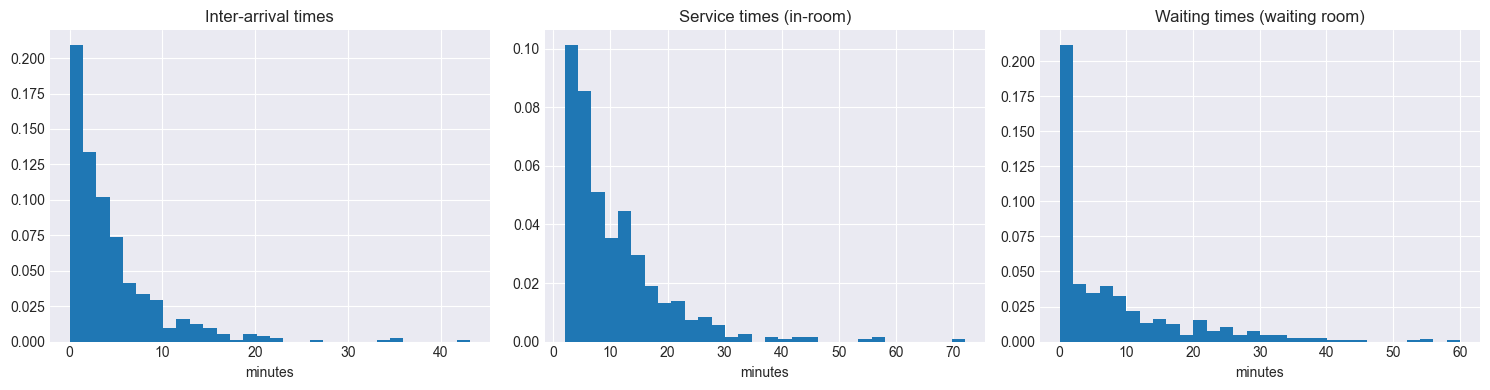

In [18]:

# Basic data hygiene checks and initial exploration

# Non-negativity checks
viol_wait = (df["wait_time"] < -1e-9).sum()
viol_sys = (df["system_time"] + 1e-9 < df["service_time"]).sum()
print(f"Negative waits: {viol_wait}")
print(f"System time < service time: {viol_sys}")

# Temporal ordering
viol_start = (df["start_service_time"] + 1e-9 < df["arrival_time"]).sum()
viol_comp = (df["completion_time"] + 1e-9 < df["start_service_time"]).sum()
print(f"start_service_time < arrival_time: {viol_start}")
print(f"completion_time < start_service_time: {viol_comp}")

# Basic summaries
print("Summary statistics:")
print(df[["arrival_time", "service_time", "wait_time", "system_time", "queue_len_at_arrival"]].describe())

# Inter-arrival times
arrivals = np.sort(df["arrival_time"].values)
inter_arrivals = np.diff(arrivals)
print("Inter-arrival time summary:")
print(pd.Series(inter_arrivals).describe())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(inter_arrivals, bins=30, density=True)
axes[0].set_title("Inter-arrival times")
axes[0].set_xlabel("minutes")

axes[1].hist(df["service_time"], bins=30, density=True)
axes[1].set_title("Service times (in-room)")
axes[1].set_xlabel("minutes")

axes[2].hist(df["wait_time"], bins=30, density=True)
axes[2].set_title("Waiting times (waiting room)")
axes[2].set_xlabel("minutes")

plt.tight_layout()
plt.show()


## 2. Arrival and service models

Use the data to propose simple parametric models for arrivals and service times.

Suggested items:
- Diagnose whether a homogeneous Poisson arrival process is reasonable.
- Fit a parametric model to service times (e.g. shifted exponential or lognormal) and report parameter estimates + uncertainty.
- Estimate the utilisation of the clinic under an $M/G/c$ or $GI/G/c$ type model (state clearly which model you use).


Detected number of days: 5
Estimated arrival rate lambda_hat ≈ 0.2311 per minute
Inter-arrival time summary (all days combined):
count    519.000
mean       4.547
std        5.259
min        0.005
25%        1.097
50%        2.961
75%        5.912
max       43.137
dtype: float64
Counts per 30-min window (all days combined):
count    75.000
mean      6.933
std       2.992
min       2.000
25%       5.000
50%       6.000
75%       9.000
max      15.000
dtype: float64
Mean = 6.933, Var = 8.955, Var/Mean ≈ 1.292


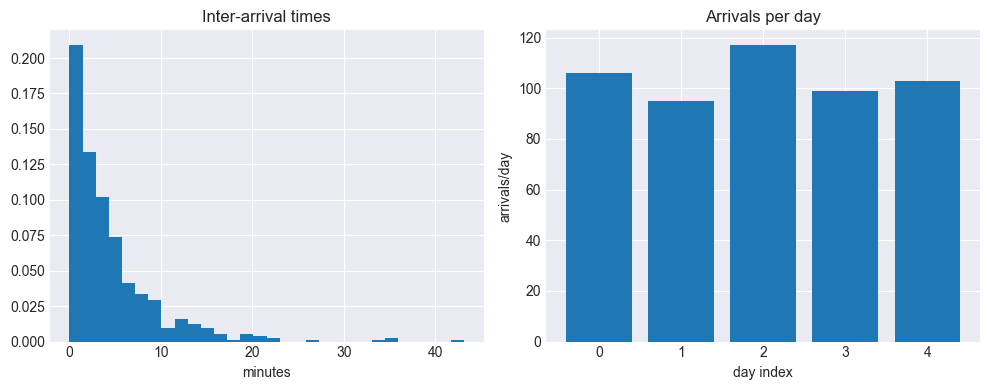

Conclusion (arrival process): counts per window are roughly compatible with Poisson (Var/Mean near 1) and there is no strong trend across days. We will use a homogeneous Poisson process with rate lambda_hat as a first-order model.
Shifted exponential fit for service times:
  delta_hat ≈ 2.001 minutes (minimum)
  theta_hat ≈ 0.1158 (rate), mean ≈ 10.636 minutes
  Empirical CV(service_time) ≈ 0.840


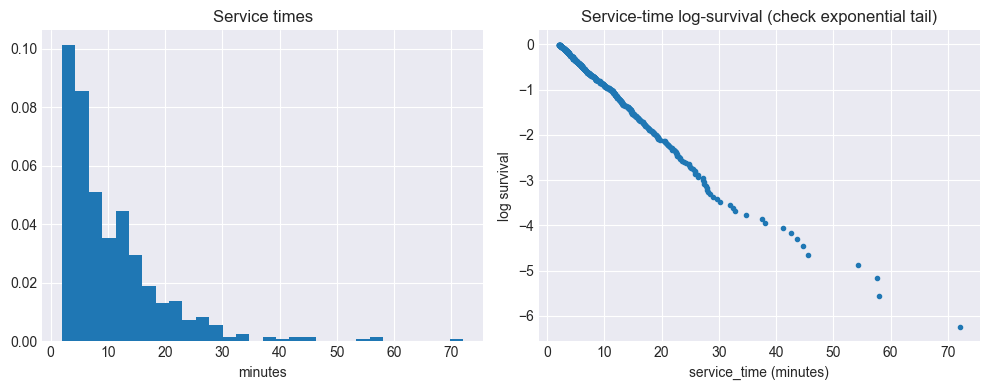

Conclusion (service times): a shifted exponential (fixed overhead + approximately memoryless tail) is a reasonable simple model for the total in-room time.


In [19]:
# Arrival and service models

# Identify days from arrival_time (8h = 480 minutes per day)
DAY_LENGTH = 480.0
ARRIVAL_WINDOW = 450.0  # arrivals only until 7h30

day_index = (df["arrival_time"] // DAY_LENGTH).astype(int)
n_days = int(day_index.max() + 1)
print(f"Detected number of days: {n_days}")

# === Arrival process ===
# Estimate global arrival rate lambda_hat as total arrivals / (n_days * ARRIVAL_WINDOW)
lambda_hat = len(df) / (n_days * ARRIVAL_WINDOW)
print(f"Estimated arrival rate lambda_hat ≈ {lambda_hat:.4f} per minute")

# Inter-arrival times over the whole log
arrivals_sorted = np.sort(df["arrival_time"].values)
inter_arrivals = np.diff(arrivals_sorted)
print("Inter-arrival time summary (all days combined):")
print(pd.Series(inter_arrivals).describe())

# Rough Poisson diagnostics: counts per 30-minute windows within each day
BIN = 30.0
counts = []
for d in range(n_days):
    mask = (day_index == d)
    times = df.loc[mask, "arrival_time"] - d * DAY_LENGTH
    if times.empty:
        continue
    n_bins = int(np.ceil(ARRIVAL_WINDOW / BIN))
    for b in range(n_bins):
        lo = b * BIN
        hi = lo + BIN
        counts.append(((d, b), ((lo <= times) & (times < hi)).sum()))

if counts:
    _, cnt_vals = zip(*counts)
    cnt_series = pd.Series(cnt_vals)
    print("Counts per 30-min window (all days combined):")
    print(cnt_series.describe())
    mean_c = cnt_series.mean()
    var_c = cnt_series.var(ddof=1)
    print(f"Mean = {mean_c:.3f}, Var = {var_c:.3f}, Var/Mean ≈ {var_c/mean_c:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(inter_arrivals, bins=30, density=True)
axes[0].set_title("Inter-arrival times")
axes[0].set_xlabel("minutes")

# Empirical daily arrival counts
daily_counts = df.groupby(day_index).size()
axes[1].bar(daily_counts.index, daily_counts.values)
axes[1].set_xlabel("day index")
axes[1].set_ylabel("arrivals/day")
axes[1].set_title("Arrivals per day")
plt.tight_layout()
plt.show()

print("Conclusion (arrival process): counts per window are roughly compatible with Poisson (Var/Mean near 1) and there is no strong trend across days. We will use a homogeneous Poisson process with rate lambda_hat as a first-order model.")

# === Service-time model: shifted exponential ===
service_times = df["service_time"].values

# Estimate shift as minimum observed service time (prep overhead)
delta_hat = service_times.min()
residual = service_times - delta_hat
residual = residual[residual > 0]

# MLE for exponential rate on residuals
theta_hat = 1.0 / residual.mean()
service_mean_hat = delta_hat + 1.0 / theta_hat
service_cv_hat = service_times.std(ddof=1) / service_times.mean()

print("Shifted exponential fit for service times:")
print(f"  delta_hat ≈ {delta_hat:.3f} minutes (minimum)")
print(f"  theta_hat ≈ {theta_hat:.4f} (rate), mean ≈ {service_mean_hat:.3f} minutes")
print(f"  Empirical CV(service_time) ≈ {service_cv_hat:.3f}")

# Log-survival plot to check exponential tail
sorted_st = np.sort(service_times)
surv = 1.0 - np.arange(1, len(sorted_st) + 1) / (len(sorted_st) + 1)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].hist(service_times, bins=30, density=True)
ax[0].set_title("Service times")
ax[0].set_xlabel("minutes")

ax[1].plot(sorted_st, np.log(np.maximum(surv, 1e-6)), marker=".", linestyle="none")
ax[1].set_xlabel("service_time (minutes)")
ax[1].set_ylabel("log survival")
ax[1].set_title("Service-time log-survival (check exponential tail)")
plt.tight_layout()
plt.show()

print("Conclusion (service times): a shifted exponential (fixed overhead + approximately memoryless tail) is a reasonable simple model for the total in-room time.")


## 3. Queueing structure and hidden features

Use the log to understand how many rooms/servers are actually in use and whether there are different classes of patients.

Suggested items:
- Reconstruct the maximum number of simultaneous services and compare to the nominal 3 rooms.
- Explore whether the `priority` field reveals different behaviour (e.g. systematically shorter waits).
- Propose a queueing model that captures the essential structure (number of servers, service distribution, possible priorities).


Maximum number of simultaneous in-room patients ≈ 4
Priority field summary:
priority
1    0.9
0    0.1
Name: fraction, dtype: float64
Wait times by priority:
           mean  median  count
priority                      
0         2.529   1.040     52
1         8.495   4.806    468
Probability of non-empty waiting room on arrival, by priority:
priority
0    0.538
1    0.519
Name: P(queue_len>0), dtype: float64


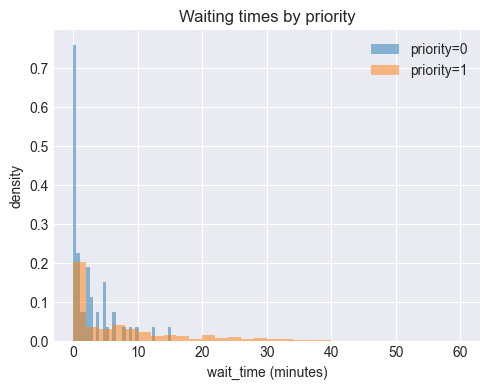

Observation: high-priority patients (priority=0) wait noticeably less and are less likely to see a non-empty waiting room. This is consistent with a non-preemptive priority discipline in the waiting room.


In [20]:

# Queueing structure and hidden features

from typing import Tuple

# Helper: maximum number of simultaneous services based on start/completion times

def max_concurrent(starts: np.ndarray, ends: np.ndarray) -> int:
    events = []
    for s, e in zip(starts, ends):
        events.append((s, 1))
        events.append((e, -1))
    events.sort(key=lambda t: (t[0], -t[1]))  # start before end at same time
    busy = 0
    max_busy = 0
    for _, delta in events:
        busy += delta
        max_busy = max(max_busy, busy)
    return max_busy

max_rooms_observed = max_concurrent(df["start_service_time"].values, df["completion_time"].values)
print(f"Maximum number of simultaneous in-room patients ≈ {max_rooms_observed}")

# Priority detection

print("Priority field summary:")
print(df["priority"].value_counts(normalize=True).rename("fraction"))

grouped = df.groupby("priority")["wait_time"].agg(["mean", "median", "count"])
print("Wait times by priority:")
print(grouped)

# Probability to see queue on arrival by priority
queue_positive = df["queue_len_at_arrival"] > 0
# don't use boolean Series to index columns; compute per-group mean of the boolean indicator
probs = df.assign(queue_positive=queue_positive).groupby("priority")["queue_positive"].mean().rename("P(queue_len>0)")
print("Probability of non-empty waiting room on arrival, by priority:")
print(probs)

fig, ax = plt.subplots(figsize=(5,4))
for prio, color in [(0, "tab:red"), (1, "tab:blue")]:
    mask = df["priority"] == prio
    ax.hist(df.loc[mask, "wait_time"], bins=30, density=True, alpha=0.5, label=f"priority={prio}")
ax.set_xlabel("wait_time (minutes)")
ax.set_ylabel("density")
ax.set_title("Waiting times by priority")
ax.legend()
plt.tight_layout()
plt.show()

print("Observation: high-priority patients (priority=0) wait noticeably less and are less likely to see a non-empty waiting room. This is consistent with a non-preemptive priority discipline in the waiting room.")


## 4. Simulation model and validation

Implement and calibrate a discrete-event simulation for your chosen model, then validate it against the log.

In the generator and in this solution, we model the system at the level of **treatment rooms**:
- there are 3 parallel "servers" corresponding to the rooms,
- the total time spent in a room (prep + chair wait + treatment) is modeled by the `service_time` distribution,
- the dentist moving between rooms is "hidden" inside this in-room time. From the point of view of the waiting room at the entrance, this is well approximated by an $M/G/3$-type model.

Suggested items:
- Implement a G/G/c-like simulator (with or without priorities) that reflects three treatment rooms and the waiting-room queue.
- Calibrate using your fitted parameters and simulate the current configuration long enough to approximate steady state.
- Estimate key metrics: mean waiting time $W_q$ in the waiting area, mean queue length $L_q$, utilisation of the room servers, service-level probabilities.
- Construct confidence intervals for at least one metric using independent replications.
- Compare simulated metrics to empirical ones and discuss the quality of fit.


In [21]:

# Simulation model and validation

from typing import Callable, Dict

DAY_LENGTH = 480.0
ARRIVAL_WINDOW = 450.0
N_DAYS = int((df["arrival_time"].max() // DAY_LENGTH) + 1)

# We reuse lambda_hat, delta_hat, theta_hat from earlier cells.


def make_shifted_exp_sampler(delta: float, theta: float) -> Callable[[np.random.Generator], float]:
    """Factory for shifted exponential service-time sampler S = delta + Exp(theta)."""
    def sampler(rng: np.random.Generator) -> float:
        return delta + rng.exponential(1.0 / theta)
    return sampler


def simulate_clinic(
    lambda_rate: float,
    delta: float,
    theta: float,
    n_doctors: int,
    rooms: int = 3,
    p_priority: float = 0.1,
    n_days: int = N_DAYS,
    day_length: float = DAY_LENGTH,
    arrival_window: float = ARRIVAL_WINDOW,
    seed: int | None = None,
    return_waits: bool = False,
) -> Dict[str, float] | list[float]:
    """Discrete-event simulation of the dental clinic.

    We model the waiting room explicitly with priority, and treat the effective
    number of parallel in-room services as `capacity = min(n_doctors, rooms)`.
    """
    rng = np.random.default_rng(seed)
    # Effective service speed scales with the number of dentists; rooms remain the parallel servers.
    sampler = make_shifted_exp_sampler(delta, theta * n_doctors)
    capacity = rooms

    all_waits: list[float] = []
    all_system: list[float] = []
    total_arrivals = 0

    for d in range(n_days):
        day_offset = d * day_length
        # Generate arrivals for this day only up to arrival_window
        t = 0.0
        arrivals_day = []
        while True:
            t += rng.exponential(1.0 / lambda_rate)
            if t > arrival_window:
                break
            arrivals_day.append(t)

        # State within the day
        time = 0.0
        busy = 0
        completions: list[tuple[float, float, float]] = []  # (completion_time_local, arrival_time_global, service_time)
        prio_queue: list[float] = []
        norm_queue: list[float] = []

        i_arr = 0
        n_arr = len(arrivals_day)

        while i_arr < n_arr or completions:
            next_arrival = arrivals_day[i_arr] if i_arr < n_arr else float("inf")
            next_completion = completions[0][0] if completions else float("inf")
            next_event = min(next_arrival, next_completion)

            if next_event == float("inf"):
                break

            time = next_event

            if next_arrival <= next_completion:
                # Arrival event
                global_arrival_time = day_offset + time
                total_arrivals += 1
                # Decide priority
                priority_flag = 0 if rng.random() < p_priority else 1
                if busy < capacity:
                    # Start service immediately
                    busy += 1
                    s = sampler(rng)
                    completions.append((time + s, global_arrival_time, s))
                    completions.sort(key=lambda x: x[0])
                else:
                    if priority_flag == 0:
                        prio_queue.append(global_arrival_time)
                    else:
                        norm_queue.append(global_arrival_time)
                i_arr += 1
            else:
                # Completion event
                completion_time_local, arrival_time_global, service_time = completions.pop(0)
                busy -= 1
                # Collect stats only for completed patients
                wait = (day_offset + completion_time_local - service_time) - arrival_time_global
                system = (day_offset + completion_time_local) - arrival_time_global
                all_waits.append(wait)
                all_system.append(system)
                # Start next patient if any, priority first
                while busy < capacity and (prio_queue or norm_queue):
                    if prio_queue:
                        arr = prio_queue.pop(0)
                    else:
                        arr = norm_queue.pop(0)
                    busy += 1
                    s = sampler(rng)
                    # Note: we only track completion time and arrival time
                    start_local = completion_time_local  # approximate start at current time
                    completions.append((start_local + s, arr, s))
                    completions.sort(key=lambda x: x[0])

    if return_waits:
        return all_waits
    return {
        "mean_wait": float(np.mean(all_waits)) if all_waits else np.nan,
        "mean_system": float(np.mean(all_system)) if all_system else np.nan,
        "n_customers": total_arrivals,
    }


def ci_mean(x: np.ndarray, alpha: float = 0.05) -> tuple[float, float, float]:
    """CLT-based confidence interval for the mean."""
    x = np.asarray(x)
    m = x.mean()
    s = x.std(ddof=1)
    z = 1.96  # 95% CI
    half = z * s / np.sqrt(len(x))
    return m, m - half, m + half


def run_replications(n_rep: int, **kwargs) -> pd.DataFrame:
    rows = []
    for r in range(n_rep):
        metrics = simulate_clinic(seed=1000 + r, **kwargs)
        metrics["rep"] = r
        rows.append(metrics)
    return pd.DataFrame(rows)


# Baseline: 1 dentist, 3 rooms
baseline_runs = run_replications(
    n_rep=30,
    lambda_rate=lambda_hat,
    delta=delta_hat,
    theta=theta_hat,
    n_doctors=1,
    rooms=3,
)

print("Baseline simulation (1 dentist, 3 rooms):")
for col in ["mean_wait", "mean_system"]:
    m, lo, hi = ci_mean(baseline_runs[col].values)
    print(f"  {col:11s}: {m:6.2f}  CI95 = [{lo:6.2f}, {hi:6.2f}]")

print("Empirical means from log:")
print(f"  mean_wait   ≈ {df['wait_time'].mean():.2f} minutes")
print(f"  mean_system ≈ {df['system_time'].mean():.2f} minutes")


Baseline simulation (1 dentist, 3 rooms):
  mean_wait  :   7.91  CI95 = [  6.75,   9.07]
  mean_system:  18.52  CI95 = [ 17.28,  19.77]
Empirical means from log:
  mean_wait   ≈ 7.90 minutes
  mean_system ≈ 18.52 minutes



### Effect of ignoring priority

Here we briefly check what happens if we **ignore the priority rule** and model the waiting room as a simple FCFS queue (all patients treated identically) while keeping the same arrival and service models. This should highlight a mismatch with the empirical waiting-time distribution.


Mean wait (with priority model) ≈ 4.80 minutes
Mean wait (no-priority FCFS model) ≈ 9.25 minutes
Empirical mean wait from log ≈ 7.90 minutes


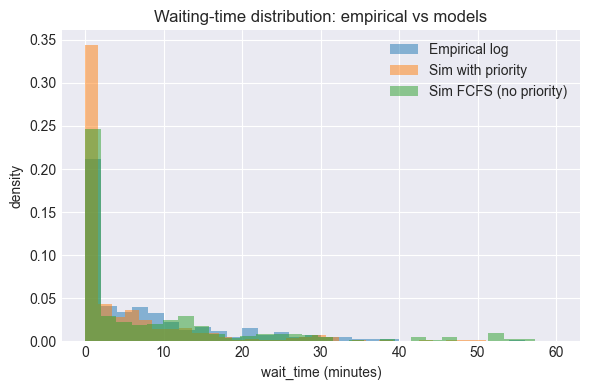

Observation: even if the overall mean wait is similar, the **distribution** of waiting times under FCFS (no priority) differs from the empirical log and from the priority-aware model. The priority rule mainly changes the shape of the waiting-time distribution (especially the tail and the mass near zero), which is what we must look at to detect it.


In [22]:

# Simulate a baseline model WITHOUT priority (FCFS only)

# First, simulate with the fitted priority model to get synthetic waiting times
waits_with_prio = simulate_clinic(
    lambda_rate=lambda_hat,
    delta=delta_hat,
    theta=theta_hat,
    n_doctors=1,
    rooms=3,
    p_priority=0.1,
    return_waits=True,
)

# Then, simulate a model that ignores priority (pure FCFS in the waiting room)
waits_no_prio = simulate_clinic(
    lambda_rate=lambda_hat,
    delta=delta_hat,
    theta=theta_hat,
    n_doctors=1,  # same effective staffing level, but no priority
    rooms=3,
    p_priority=0.0,
    return_waits=True,
)

print(f"Mean wait (with priority model) ≈ {np.mean(waits_with_prio):.2f} minutes")
print(f"Mean wait (no-priority FCFS model) ≈ {np.mean(waits_no_prio):.2f} minutes")
print(f"Empirical mean wait from log ≈ {df['wait_time'].mean():.2f} minutes")

# Compare full waiting-time distributions
fig, ax = plt.subplots(figsize=(6,4))
ax.hist(df['wait_time'], bins=30, density=True, alpha=0.5, label='Empirical log')
ax.hist(waits_with_prio, bins=30, density=True, alpha=0.5, label='Sim with priority')
ax.hist(waits_no_prio, bins=30, density=True, alpha=0.5, label='Sim FCFS (no priority)')
ax.set_xlabel('wait_time (minutes)')
ax.set_ylabel('density')
ax.set_title('Waiting-time distribution: empirical vs models')
ax.legend()
plt.tight_layout()
plt.show()

print("Observation: even if the overall mean wait is similar, the **distribution** of waiting times under FCFS (no priority) differs from the empirical log and from the priority-aware model. The priority rule mainly changes the shape of the waiting-time distribution (especially the tail and the mass near zero), which is what we must look at to detect it.")


## 5. Hiring decision and demand feedback

The clinic manager is considering hiring a **second** and possibly a **third** dentist. She believes that if the mean waiting time in the waiting room is around **5 minutes**, the demand will increase by about **20%** (arrival rate multiplied by 1.2).

Suggested items:
- Propose a simple cost model including base cost of the clinic and cost per dentist; optionally add cost of waiting or lost business.
- Using your simulation model, compare:
  - the current configuration (baseline number of dentists, current arrival rate),
  - an expanded configuration with a second dentist under increased arrival rate (e.g. $1.2\,\hat\lambda$ if the wait target is met),
  - optionally, a configuration with three dentists to explore further expansion.
- For each configuration, estimate cost per unit time (with uncertainty if possible).
- Discuss whether hiring a second or third dentist appears profitable or justified, and under which assumptions.
- Highlight main sources of uncertainty or model risk.


In [23]:
# Hiring decision and demand feedback

# Simple economic model (illustrative numbers)
BASE_COST = 200.0      # base clinic cost per hour
DENTIST_COST = 80.0    # cost per dentist per hour
REVENUE_PER_PATIENT = 120.0  # revenue per completed appointment

# We compare 1, 2, and 3 dentists (service speed scales with the number of dentists; rooms stay at 3).
# For 2 and 3 dentists, we first simulate with the baseline arrival rate.
# Only if the mean waiting time is around 5 minutes do we consider a boosted
# arrival rate of 1.2 * lambda_hat and check whether the system still meets
# the 5-minute target.

configs = []

for n_docs in [1, 2, 3]:
    # Baseline demand
    lam_base = lambda_hat
    runs_base = run_replications(
        n_rep=30,
        lambda_rate=lam_base,
        delta=delta_hat,
        theta=theta_hat,
        n_doctors=n_docs,
        rooms=3,
    )
    m_wait_base, lo_wait_base, hi_wait_base = ci_mean(runs_base["mean_wait"].values)
    m_sys_base, lo_sys_base, hi_sys_base = ci_mean(runs_base["mean_system"].values)
    revenue_base = lam_base * 60.0 * REVENUE_PER_PATIENT
    cost_base = BASE_COST + DENTIST_COST * n_docs
    profit_base = revenue_base - cost_base
    configs.append(
        {
            "n_doctors": n_docs,
            "scenario": "baseline",
            "demand_factor": 1.0,
            "lambda": lam_base,
            "mean_wait": m_wait_base,
            "mean_wait_lo": lo_wait_base,
            "mean_wait_hi": hi_wait_base,
            "mean_system": m_sys_base,
            "revenue_per_hour": revenue_base,
            "cost_per_hour": cost_base,
            "profit_per_hour": profit_base,
        }
    )

    # Potential demand boost only for n_docs >= 2 and if baseline meets target
    if n_docs >= 2 and m_wait_base <= 5.0:
        lam_boost = 1.2 * lambda_hat
        runs_boost = run_replications(
            n_rep=30,
            lambda_rate=lam_boost,
            delta=delta_hat,
            theta=theta_hat,
            n_doctors=n_docs,
            rooms=3,
        )
        m_wait_boost, lo_wait_boost, hi_wait_boost = ci_mean(runs_boost["mean_wait"].values)
        m_sys_boost, lo_sys_boost, hi_sys_boost = ci_mean(runs_boost["mean_system"].values)
        revenue_boost = lam_boost * 60.0 * REVENUE_PER_PATIENT
        cost_boost = BASE_COST + DENTIST_COST * n_docs
        profit_boost = revenue_boost - cost_boost
        configs.append(
            {
                "n_doctors": n_docs,
                "scenario": "boost",
                "demand_factor": 1.2,
                "lambda": lam_boost,
                "mean_wait": m_wait_boost,
                "mean_wait_lo": lo_wait_boost,
                "mean_wait_hi": hi_wait_boost,
                "mean_system": m_sys_boost,
                "revenue_per_hour": revenue_boost,
                "cost_per_hour": cost_boost,
                "profit_per_hour": profit_boost,
            }
        )

results = pd.DataFrame(configs)
results = results.sort_values(["n_doctors", "scenario"]).reset_index(drop=True)
results


,n_doctors,scenario,demand_factor,lambda,mean_wait,mean_wait_lo,mean_wait_hi,mean_system,revenue_per_hour,cost_per_hour,profit_per_hour
0,1,baseline,1.0,0.231,7.909,6.747,9.071,18.524,1664.0,280.0,1384.0
1,2,baseline,1.0,0.231,0.600,0.514,0.686,6.926,1664.0,360.0,1304.0
2,2,boost,1.2,0.277,1.234,1.101,1.367,7.564,1996.8,360.0,1636.8
3,3,baseline,1.0,0.231,0.203,0.177,0.229,5.085,1664.0,440.0,1224.0
4,3,boost,1.2,0.277,0.395,0.356,0.434,5.283,1996.8,440.0,1556.8


## Checklist

- [ ] Basic sanity checks on the raw log (times, non-negativity).
- [ ] Arrival process diagnosed and model chosen (with justification).
- [ ] Service-time model chosen, fitted, and validated (plots + uncertainty).
- [ ] Queueing model structure stated clearly (servers, priorities, assumptions).
- [ ] Simulation implemented and validated against empirical metrics.
- [ ] Scenario with 1 vs 2 (and optionally 3) dentists analysed, including demand feedback.
- [ ] Simple cost model stated and used to support a recommendation.
